In [1]:
import yfinance as yf
import pandas as pd
import numpy
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

In [5]:
signaux = pd.read_csv("resultat_test.csv", index_col="Date", parse_dates=['Date'])
signaux.head()

,rendement_w,rendement_w1,rendements_w4,volat_glissante_w4,cible,proba_hausse_foret,prediction_random_forest,proba_hausse_logistique,prediction_regression_logistique
Date,,,,,,,,,
2024-01-01,-0.015548,0.018721,0.020898,0.016348,True,0.64,True,0.590944,True
2024-01-08,0.018721,0.012063,0.015661,0.014447,True,0.52,True,0.589091,True
2024-01-15,0.012063,0.010323,0.018537,0.014857,True,0.65,True,0.589330,True
2024-01-22,0.010323,0.014238,0.025457,0.015066,True,0.53,True,0.588992,True
2024-01-29,0.014238,0.013857,0.056484,0.003629,True,0.47,False,0.587229,True


In [26]:
capital_init = 100
rendement_foret = signaux['rendement_w1'] * signaux['prediction_random_forest']
capital = capital_init * (1 + rendement_foret).cumprod()

# Buy and hold
buy_and_hold = capital_init * (1 + signaux['rendement_w1']).cumprod()

# Le regression logistique ca sert a rien car c'est égal au buy and hold 

print(f"Forêt aléatoire {(capital.iloc[-1] / capital_init - 1):.2%}")
print(f"Buy & hold {(buy_and_hold.iloc[-1] / capital_init - 1):.2%}")

Forêt aléatoire 24.04%
Buy & hold 66.79%


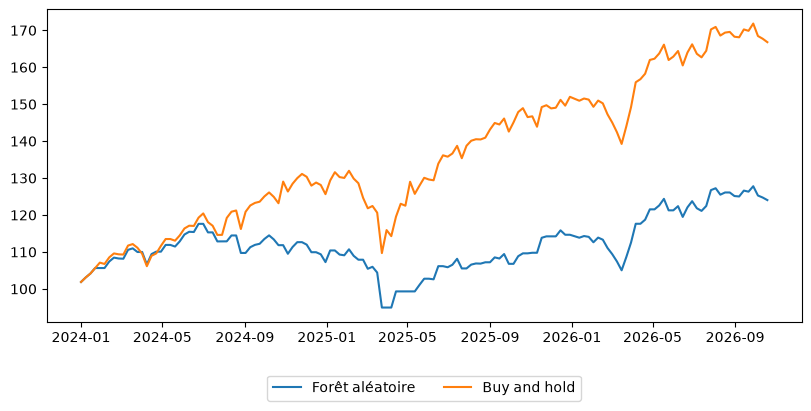

In [25]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(capital, label="Forêt aléatoire")
ax.plot(buy_and_hold, label="Buy and hold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)

 Rendements random forest 23.56%
 Rendements buy and hold 54.05%
